# Play around with surface temperature data from CMIP6 G1 experiments
This is 

In [1]:
import sys
import os
import inspect
from matplotlib.lines import Line2D
from glob import glob


from isca_tools.thesis.adiabat_theory import get_temp_adiabat
from isca_tools.thesis.season_annual_harmonic import get_phase_amp
from isca_tools.thesis.surface_flux_taylor_2layer import get_sensitivity_lh
from isca_tools.utils.moist_physics import sphum_sat
from isca_tools.utils.numerical import sum_complex
from isca_tools.thesis.lapse_integral_simple import get_lnb_ind, get_temp_2_layer_approx
from isca_tools.utils.xarray import wrap_with_apply_ufunc, isel_float
from isca_tools.utils.numerical import spline_deriv_nonperiodic
from isca_tools.utils.land import get_land_coords, get_ocean_coords

# REMOTE - So can access functions in isca_tools which is in home/Isca directory
# sys.path.append(os.path.join(os.environ['HOME'], 'Isca'))
# LOCAL - So can access functions in isca_tools which is in StAndrews/Isca
sys.path.append(os.environ['PWD'])
from isca_tools.utils.constants import kappa, L_v, c_p, c_p_ocean, rho_ocean, Stefan_Boltzmann, R, R_v, g, radius_earth, lapse_dry

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
from isca_tools.plot import fig_resize, update_fontsize, update_linewidth, savefig, label_subplots
import isca_tools
from isca_tools.utils.load import load_namelist
from isca_tools.utils.base import mass_weighted_vertical_integral
# Use custom matplotlib style for publishing
plt.style.use('/Users/joshduffield/Documents/StAndrews/Isca/jobs/tau_sweep/aquaplanet/publish_figures/publish.mplstyle')
ax_linewidth = plt.rcParams['axes.linewidth']

from jobs.thesis_season.publish_figs.load import day_seconds
from jobs.thesis_season.publish_figs.xr_funcs import get_fourier_fit_xr, fourier_series_xr

In [2]:
data_dir = '/Users/joshduffield/Documents/StAndrews/Isca/jobs/nerc_srm/data/raw'
model = 'IPSL-CM6A-LR'
exp = ['piControl', 'G1']
n_exp = len(exp)
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
ds_base = []
ds = []
lat_min = 30
for i in range(len(exp)):
    pattern = f"{data_dir}/CMIP6/ts_Amon_{model}_{exp[i]}_*.nc"
    files = sorted(glob(pattern))
    ds_use = xr.open_mfdataset(files, decode_times=time_coder).ts
    ds_base.append(ds_use.where(np.abs(ds_use.lat) > lat_min).load())
    # ds_base.append(xr.open_dataset(files[0], decode_times=time_coder).ts.load())
    ds.append(ds_base[i].groupby('time.month').mean('time'))

In [11]:
months = np.arange(1, 13)
days = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
edges = np.r_[0, days.cumsum()]
midpoints = (edges[:-1] + edges[1:]) / 2
period = edges[-1]
omega = 2 * np.pi / period

# Mean of each basis function over each calendar month.
X = np.column_stack([
    np.ones(12),
    np.diff(np.sin(omega * edges)) / (omega * days),
    -np.diff(np.cos(omega * edges)) / (omega * days),
    np.diff(np.sin(2 * omega * edges)) / (2 * omega * days),
    -np.diff(np.cos(2 * omega * edges)) / (2 * omega * days),
])

peak_grid = xr.DataArray(
    np.arange(0, period, 0.1),
    dims="day",
    coords={"day": np.arange(0, period, 0.1)},
)

def full_monthly_peak_day(clim: xr.DataArray) -> xr.DataArray:
    """Estimate the peak of a Fourier curve that reproduces the monthly means.

    Args:
        clim: Climatology with a month coordinate labelled 1 through 12.

    Returns:
        Peak day since the start of 1 January on the 365-day reference
        calendar. Locations with a missing month return NaN.
    """
    clim = clim.reindex(month=months)
    k = np.arange(1, 7)
    w = omega * k
    angle = edges[:, None] * w
    scale = days[:, None] * w

    # Integrate each basis function over each calendar month.
    X_full = np.column_stack([
        np.ones(12),
        np.diff(np.sin(angle), axis=0) / scale,
        -np.diff(np.cos(angle), axis=0) / scale,
    ])
    if np.linalg.matrix_rank(X_full) != 12:
        raise ValueError("The Fourier basis cannot reproduce all 12 monthly means.")

    projection = xr.DataArray(
        np.linalg.pinv(X_full),
        dims=("coef", "month"),
        coords={"month": months},
    )
    coef = xr.dot(projection, clim, dim="month")

    theta = peak_grid.values[:, None] * w
    basis = xr.DataArray(
        np.column_stack([
            np.ones(peak_grid.size),
            np.cos(theta),
            np.sin(theta),
        ]),
        dims=("day", "coef"),
        coords={"day": peak_grid.values},
    )
    fitted = xr.dot(basis, coef, dim="coef")
    return fitted.idxmax("day").where(clim.notnull().all("month"))


def seasonal_peak_days(clim: xr.DataArray) -> xr.Dataset:
    """Estimate climatological peak days by three methods.

    Args:
        clim: Climatology with a month coordinate labelled 1 through 12.

    Returns:
        Peak days since the start of 1 January for the unfitted monthly
        climatology, annual harmonic, and annual-plus-semiannual fit.
        Locations missing any climatological month return NaN.
    """
    complete = clim.notnull().all("month")

    monthly_peak = (
        clim.rename(month="day")
        .assign_coords(day=midpoints)
        .idxmax("day")
    )

    p1 = xr.DataArray(
        np.linalg.pinv(X[:, :3]),
        dims=("coef", "month"),
        coords={"coef": ["mean", "cos1", "sin1"], "month": months},
    )
    c1 = xr.dot(p1, clim, dim="month")
    a1 = c1.sel(coef="cos1", drop=True)
    b1 = c1.sel(coef="sin1", drop=True)
    annual_peak = (np.arctan2(b1, a1) / omega) % period

    terms = ["mean", "cos1", "sin1", "cos2", "sin2"]
    p2 = xr.DataArray(
        np.linalg.pinv(X),
        dims=("coef", "month"),
        coords={"coef": terms, "month": months},
    )
    c2 = xr.dot(p2, clim, dim="month")
    theta = omega * peak_grid
    basis = xr.concat(
        [xr.ones_like(theta), np.cos(theta), np.sin(theta),
         np.cos(2 * theta), np.sin(2 * theta)],
        dim=xr.IndexVariable("coef", terms),
    )
    two_harmonic_peak = xr.dot(c2, basis, dim="coef").idxmax("day")

    out = xr.Dataset({
        "monthly": monthly_peak,
        "one_harmonic": annual_peak,
        "two_harmonic": two_harmonic_peak,
        "full_harmonic": full_monthly_peak_day(clim),
    }).where(complete)
    return out


temp_peak = [seasonal_peak_days(ds[i]) for i in range(n_exp)]
# solar_peak = seasonal_peak_days(insolation)

# Same 365-day calendar as the harmonic fits: day 0 = start of 1 January.
# Use the midpoint of each nominal solstice date.
june_solstice = edges[5] + (21 - 1) + 0.5       # 171.5
december_solstice = edges[11] + (21 - 1) + 0.5  # 354.5
solar_reference = xr.where(
    ds[0]["lat"] > 0, june_solstice, december_solstice
).where(ds[0]["lat"] != 0)

lag_days = [(temp_peak[i] - solar_reference + period / 2) % period - period / 2 for i in range(n_exp)]

# lag_days = (temp_peak - solar_reference + period / 2) % period - period / 2

In [13]:
lag_diff = lag_days[1] - lag_days[0]

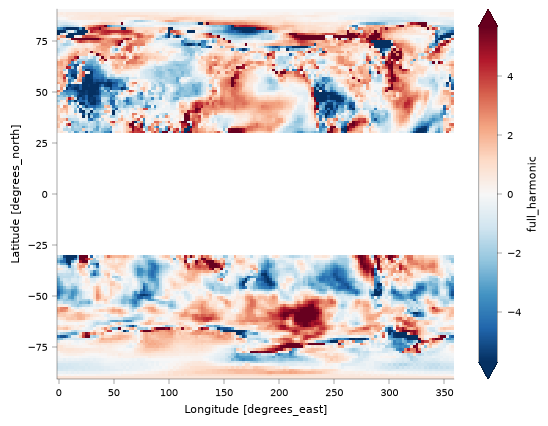

In [16]:
lag_diff.full_harmonic.plot(robust=True)

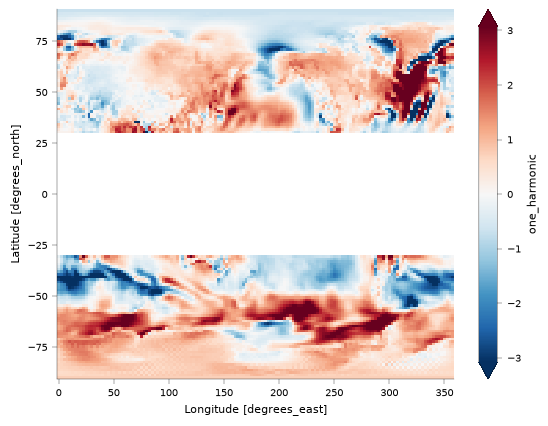

In [18]:
lag_diff.one_harmonic.plot(robust=True)

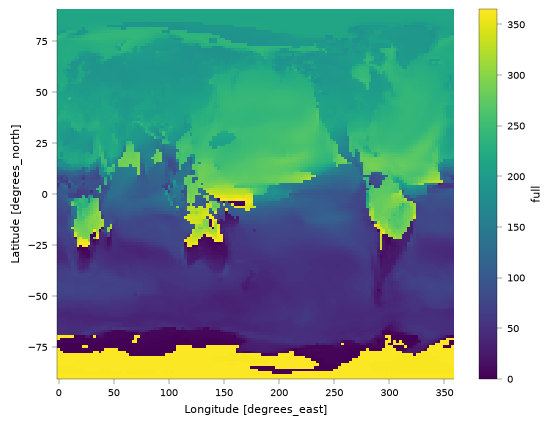

In [ ]:
temp_peak[1].full.plot()

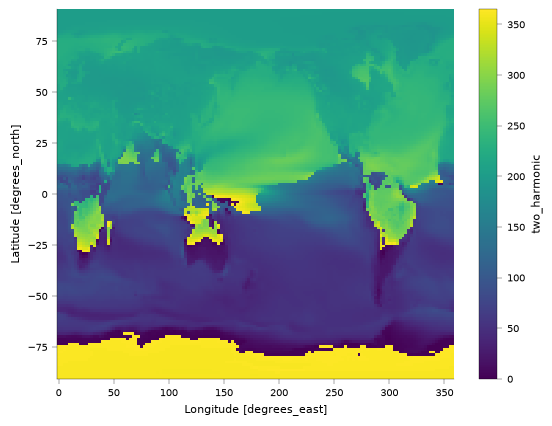

In [ ]:
temp_peak.two_harmonic.plot()

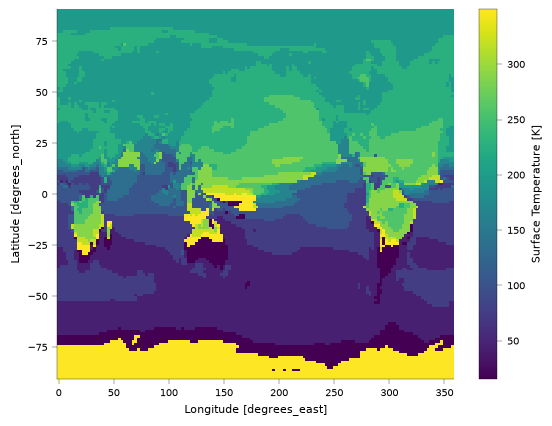

In [ ]:
temp_peak.monthly.plot()

In [ ]:
ds[0]

<xarray.DataArray 'ts' (month: 12, lat: 143, lon: 144)> Size: 988kB
array([[[243.47104, 243.47104, 243.47104, ..., 243.47104, 243.47104,
         243.47104],
        [244.94684, 244.88242, 244.80385, ..., 245.1575 , 245.08157,
         245.03934],
        [245.3965 , 245.26782, 245.13637, ..., 245.77151, 245.64859,
         245.54085],
        ...,
        [241.90263, 241.99004, 242.03503, ..., 241.68268, 241.81302,
         241.8769 ],
        [241.55038, 241.58984, 241.61409, ..., 241.47527, 241.47388,
         241.48189],
        [239.98192, 239.98192, 239.98192, ..., 239.98192, 239.98192,
         239.98192]],

       [[231.55223, 231.55223, 231.55223, ..., 231.55223, 231.55223,
         231.55223],
        [233.61034, 233.52351, 233.42949, ..., 233.84573, 233.75851,
         233.71535],
        [234.19348, 234.02808, 233.85233, ..., 234.7075 , 234.54242,
         234.39441],
...
        [248.0819 , 248.15688, 248.20024, ..., 247.88321, 247.9899 ,
         248.05333],
        [247.98785, 248.025  , 248.04816, ..., 247.91397, 247.91377,
         247.92307],
        [246.53952, 246.53952, 246.53952, ..., 246.53952, 246.53952,
         246.53952]],

       [[244.47238, 244.47238, 244.47238, ..., 244.47238, 244.47238,
         244.47238],
        [245.81432, 245.7535 , 245.67567, ..., 246.02834, 245.94823,
         245.9066 ],
        [246.22766, 246.10155, 245.97183, ..., 246.5972 , 246.47641,
         246.36763],
        ...,
        [244.0722 , 244.1542 , 244.1979 , ..., 243.86974, 243.98607,
         244.04594],
        [243.84592, 243.88745, 243.91362, ..., 243.7685 , 243.76833,
         243.77773],
        [242.347  , 242.347  , 242.347  , ..., 242.347  , 242.347  ,
         242.347  ]]], shape=(12, 143, 144), dtype=float32)
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat      (lat) float32 572B -90.0 -88.73 -87.46 -86.2 ... 87.46 88.73 90.0
  * lon      (lon) float32 576B 0.0 2.5 5.0 7.5 10.0 ... 350.0 352.5 355.0 357.5
Attributes:
    long_name:           Surface Temperature
    units:               K
    online_operation:    average
    cell_methods:        area: time: mean
    interval_operation:  900 s
    interval_write:      1 month
    standard_name:       surface_temperature
    description:         Surface temperature (skin for open ocean)
    history:             none
    cell_measures:       area: areacella

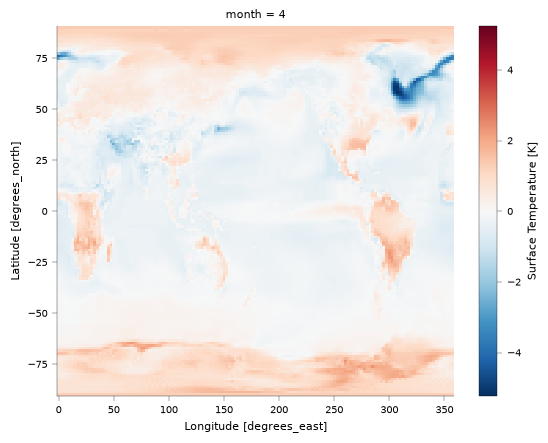

In [ ]:
(ds[1]-ds[0]).sel(month=4).plot()

In [ ]:
ds_base[1].time

<xarray.DataArray 'time' (time: 1200)> Size: 10kB
array([cftime.DatetimeGregorian(1850, 1, 16, 12, 0, 0, 0, has_year_zero=False),
       cftime.DatetimeGregorian(1850, 2, 15, 0, 0, 0, 0, has_year_zero=False),
       cftime.DatetimeGregorian(1850, 3, 16, 12, 0, 0, 0, has_year_zero=False),
       ...,
       cftime.DatetimeGregorian(1949, 10, 16, 12, 0, 0, 0, has_year_zero=False),
       cftime.DatetimeGregorian(1949, 11, 16, 0, 0, 0, 0, has_year_zero=False),
       cftime.DatetimeGregorian(1949, 12, 16, 12, 0, 0, 0, has_year_zero=False)],
      shape=(1200,), dtype=object)
Coordinates:
  * time     (time) object 10kB 1850-01-16 12:00:00 ... 1949-12-16 12:00:00
Attributes:
    axis:           T
    standard_name:  time
    long_name:      Time axis
    time_origin:    1850-01-01 00:00:00
    bounds:         time_bounds